In [1]:
# Normalization and integration
# Introduction to scRNA-seq
# Author: Harvard Chan Bioinformatics Core
# Created: August 2026

import scanpy as sc
import scvi

import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(scvi.__version__)              # 1.5.0.post1
# Load dataset
filtered_adata = sc.read_h5ad("data/filtered_adata.h5ad")

1.5.0.post1


In [2]:
# Create new adata object for normalized results
adata_phase = filtered_adata.copy()

# Saving count data
adata_phase.layers["counts"] = adata_phase.X.copy()
adata_phase

AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts'
    layers: None (.X), 'counts'

In [3]:
# Normalizing to median total counts
adata_phase.layers["median"] = adata_phase.layers["counts"].copy()
sc.pp.normalize_total(adata_phase, layer = "median")

# Logarithmize the data
adata_phase.layers["log"] = adata_phase.layers["median"].copy()
sc.pp.log1p(adata_phase, layer = "log")

# Print adata information
adata_phase

AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts'
    uns: 'log1p'
    layers: None (.X), 'counts', 'median', 'log'

In [4]:
sc.pp.highly_variable_genes(adata_phase, 
                            layer = "counts", 
                            flavor = "seurat_v3", 
                            n_top_genes = 2000, 
                            batch_key = "sample")

In [5]:
# Show newly compute highly variable columns
adata_phase.var.head()

,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,mito,log1p_mean_counts,log1p_total_counts,n_counts,highly_variable,highly_variable_rank,means,variances,variances_norm,highly_variable_nbatches
AL627309.1,12,0.000382,99.961837,12.0,False,0.000382,2.564949,12.0,False,NaN,0.000405,0.000405,0.932602,0
AL669831.5,99,0.003212,99.685155,101.0,False,0.003207,4.624973,99.0,False,NaN,0.003341,0.003465,0.920303,0
LINC00115,177,0.005915,99.437095,186.0,False,0.005898,5.231109,170.0,False,NaN,0.005738,0.006447,0.964497,0
FAM41C,136,0.004389,99.567485,138.0,False,0.004379,4.934474,134.0,False,NaN,0.004523,0.004637,0.896561,0
NOC2L,2019,0.069934,93.579061,2199.0,False,0.067597,7.696213,2139.0,False,NaN,0.072193,0.082442,0.904635,0


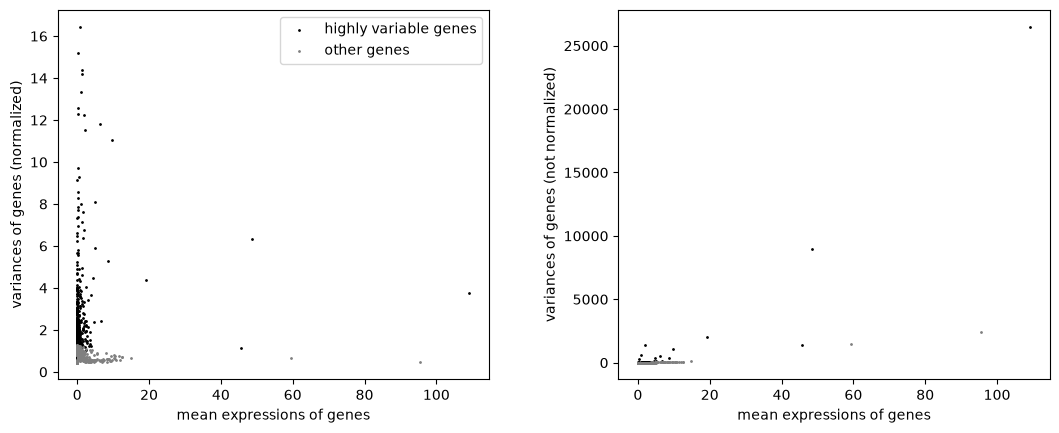

In [7]:
# Default HVG figure
sc.pl.highly_variable_genes(adata_phase)

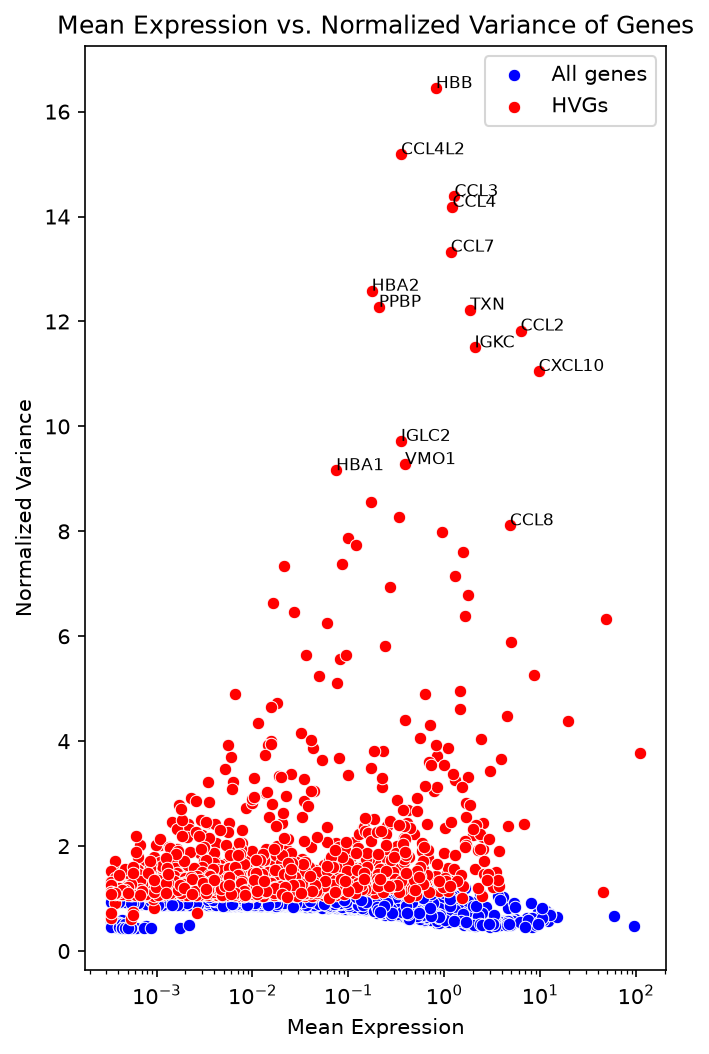

In [10]:
# Grab mean and variance for each gene
mean_expression = adata_phase.var["means"]
norm_variance = adata_phase.var["variances_norm"]

# Create a new canvas to plot on
fig, ax = plt.subplots(figsize = (5, 8), dpi = 150)

# Plot all genes in blue
sns.scatterplot(x = mean_expression,
                y = norm_variance,
                ax = ax,
                color = "blue",
                label = "All genes")

# Grab highly variable genes
# values that are True for `highly_variable`
hvg_mask = adata_phase.var["highly_variable"]

# Plot HVGs on top of original plot as red
sns.scatterplot(x = mean_expression[hvg_mask],
                y = norm_variance[hvg_mask],
                ax = ax,
                color = "red",
                label = "HVGs")

# Plot axes and titles
ax.set_xlabel("Mean Expression")
ax.set_ylabel("Normalized Variance")
ax.set_title("Mean Expression vs. Normalized Variance of Genes")
# log10 scale x-axis
ax.set_xscale("log")

# Grab top N genes
N = 15
top_genes = adata_phase.var["highly_variable_rank"].nsmallest(N).index

# Add text labels to figure
for gene_name in top_genes:
    x_value = mean_expression[gene_name]
    y_value = norm_variance[gene_name]
    ax.text(x_value, y_value, 
            gene_name, 
            fontsize = 8, color = "black")

# Show legend
plt.legend()

In [12]:
# Ensure log-normalized counts are in default .X slot
adata_phase.X = adata_phase.layers["log"].copy()

# Calculate PCA score
sc.pp.pca(adata_phase,
          n_comps = 50,
          mask_var = "highly_variable")
# Observe newly created obsm and varm slots
adata_phase

AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'log1p', 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts', 'median', 'log'

In [13]:
# First 5 PC score for first 5 cells in the dataset
adata_phase.obsm["X_pca"][1:5, 1:5]

array([[-5.4042373 ,  1.4356799 ,  1.6136886 , -0.4067187 ],
       [-5.607639  , -1.2920722 , -0.88285327,  0.45439065],
       [-5.3116064 , -1.9772382 , -0.5257096 ,  1.1217996 ],
       [-1.2440815 , -0.17928551, -1.3938781 ,  1.8702247 ]],
      dtype=float32)

In [14]:
g2m_genes = [
    "NCAPD2", "ANLN", "TACC3", "HMMR", "GTSE1", "NDC80", "AURKA", "TPX2",
    "BIRC5", "G2E3", "CBX5", "RANGAP1", "CTCF", "CDCA3", "TTK", "SMC4",
    "ECT2", "CENPA", "CDC20", "NEK2", "CENPF", "TMPO", "HJURP", "CKS2",
    "DLGAP5", "PIMREG", "TOP2A", "PSRC1", "CDCA8", "CKAP2", "NUSAP1",
    "KIF23", "KIF11", "KIF20B", "CENPE", "GAS2L3", "KIF2C", "NUF2",
    "ANP32E", "LBR", "MKI67", "CCNB2", "CDC25C", "HMGB2", "CKAP2L",
    "BUB1", "CDK1", "CKS1B", "UBE2C", "CKAP5", "AURKB", "CDCA2",
    "TUBB4B", "JPT1"]

s_genes = [
    "UBR7", "RFC2", "RAD51", "MCM2", "TIPIN", "MCM6", "UNG", "POLD3",
    "WDR76", "CLSPN", "CDC45", "CDC6", "MSH2", "MCM5", "POLA1", "MCM4",
    "RAD51AP1", "GMNN", "RPA2", "CASP8AP2", "HELLS", "E2F8", "GINS2",
    "PCNA", "NASP", "BRIP1", "DSCC1", "DTL", "CDCA7", "CENPU", "ATAD2",
    "CHAF1B", "USP1", "SLBP", "RRM1", "FEN1", "RRM2", "EXO1", "CCNE2",
    "TYMS", "BLM", "PRIM1", "UHRF1"]

In [15]:
# Cell cycle scoring
sc.tl.score_genes_cell_cycle(adata_phase, 
                             s_genes, 
                             g2m_genes)

C:\Users\user\AppData\Local\Temp\ipykernel_23732\3793311345.py:2: FutureWarning: The specified parameters ('s_genes', 'g2m_genes') are no longer positional. Please specify them like `s_genes=['UBR7', 'RFC2', 'RAD51', 'MCM2', 'TIPIN', 'MCM6', 'UNG', 'POLD3', 'WDR76', 'CLSPN', 'CDC45', 'CDC6', 'MSH2', 'MCM5', 'POLA1', 'MCM4', 'RAD51AP1', 'GMNN', 'RPA2', 'CASP8AP2', 'HELLS', 'E2F8', 'GINS2', 'PCNA', 'NASP', 'BRIP1', 'DSCC1', 'DTL', 'CDCA7', 'CENPU', 'ATAD2', 'CHAF1B', 'USP1', 'SLBP', 'RRM1', 'FEN1', 'RRM2', 'EXO1', 'CCNE2', 'TYMS', 'BLM', 'PRIM1', 'UHRF1']`
  sc.tl.score_genes_cell_cycle(adata_phase,


In [17]:
# Observe newly created cell cycle columns
adata_phase.obs.head()

,n_genes,sample,n_genes_by_counts,total_counts,cells,log10GenesPerUMI,log1p_n_genes_by_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mito,log1p_total_counts_mito,pct_counts_mito,mito_ratio,S_score,G2M_score,phase
AAACATACAATGCC-1_ctrl,874,ctrl,874,2344.0,AAACATACAATGCC-1_ctrl,0.872863,6.774224,7.760041,47.568259,59.129693,69.197952,84.044369,46.0,3.850147,1.962457,0.019625,0.005933,0.016737,G2M
AAACATACATTTCC-1_ctrl,896,ctrl,896,3125.0,AAACATACATTTCC-1_ctrl,0.844760,6.799056,8.047509,51.904000,63.456000,74.080000,87.328000,56.0,4.043051,1.792000,0.017920,0.003995,0.003142,S
AAACATACCAGAAA-1_ctrl,725,ctrl,725,2578.0,AAACATACCAGAAA-1_ctrl,0.838493,6.587550,7.855157,61.947246,69.550039,78.432894,91.272304,40.0,3.713572,1.551590,0.015516,-0.013314,-0.032831,G1
AAACATACCAGCTA-1_ctrl,979,ctrl,979,3261.0,AAACATACCAGCTA-1_ctrl,0.851262,6.887553,8.090096,52.836553,62.557498,71.879791,85.311254,45.0,3.828641,1.379945,0.013799,-0.017613,-0.001563,G1
AAACATACCATGCA-1_ctrl,362,ctrl,362,746.0,AAACATACCATGCA-1_ctrl,0.890686,5.894403,6.616065,53.887399,64.879357,78.284182,100.000000,16.0,2.833213,2.144772,0.021448,0.017205,-0.032109,S


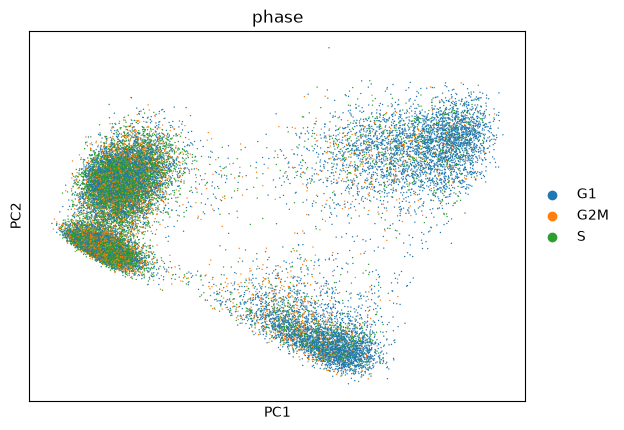

In [18]:
# PC1 vs PC2, colored by cell cycle phase
sc.pl.pca(adata_phase, 
          color = "phase")

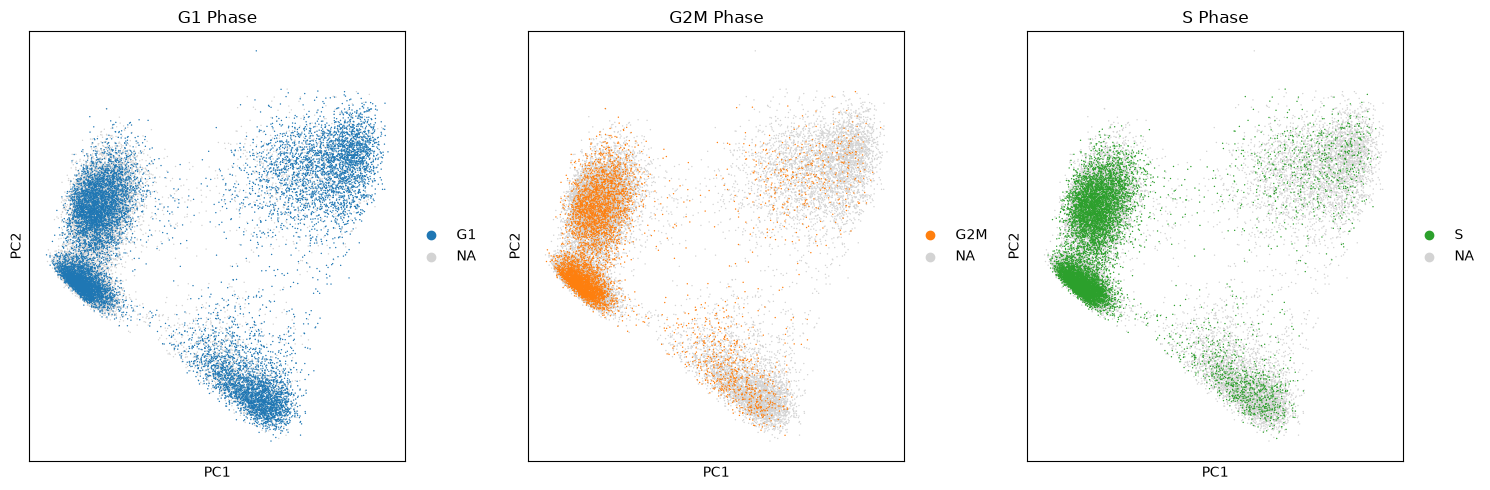

In [19]:
# Create plot with the correct dimensions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot the PCA colored by cell cycle phase
sc.pl.pca(adata_phase, color = "phase", 
          groups = "G1", ax = axes[0], 
          show = False, title = "G1 Phase")
sc.pl.pca(adata_phase, color = "phase", 
          groups = "G2M", ax = axes[1], 
          show = False, title = "G2M Phase")
sc.pl.pca(adata_phase, color = "phase", 
          groups = "S", ax = axes[2], 
          show = False, title = "S Phase")

plt.tight_layout()
plt.show()

In [20]:
# Calculate quartiles of mitochondrial ratio values
np.percentile(adata_phase.obs["pct_counts_mito"], 
              [0, 25, 50, 75, 100])

array([ 0.        ,  1.43786371,  1.99296606,  2.66920877, 14.46428585])

In [22]:
# Group cells into labels based upon mitochondrial ratio scores
adata_phase.obs["mitoFr"] = pd.cut(
    adata_phase.obs["pct_counts_mito"],
    bins = [-np.inf, 1.44, 1.99, 2.67, np.inf],
    labels = ["Low", "Medium", "Medium high", "High"])

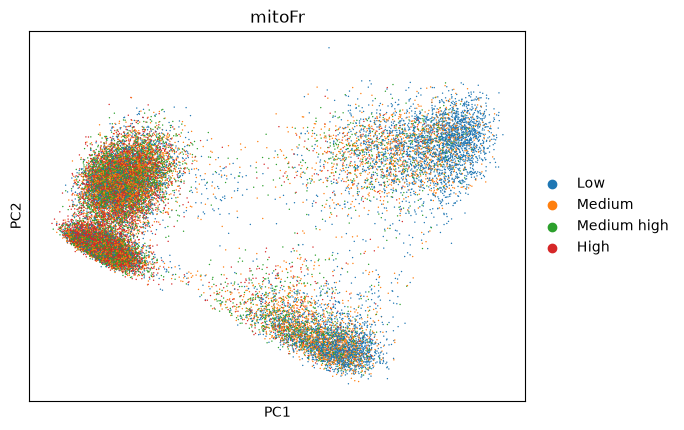

In [23]:
# PC1 vs PC2, colored by cell cycle phase
sc.pl.pca(adata_phase, 
          color = "mitoFr")

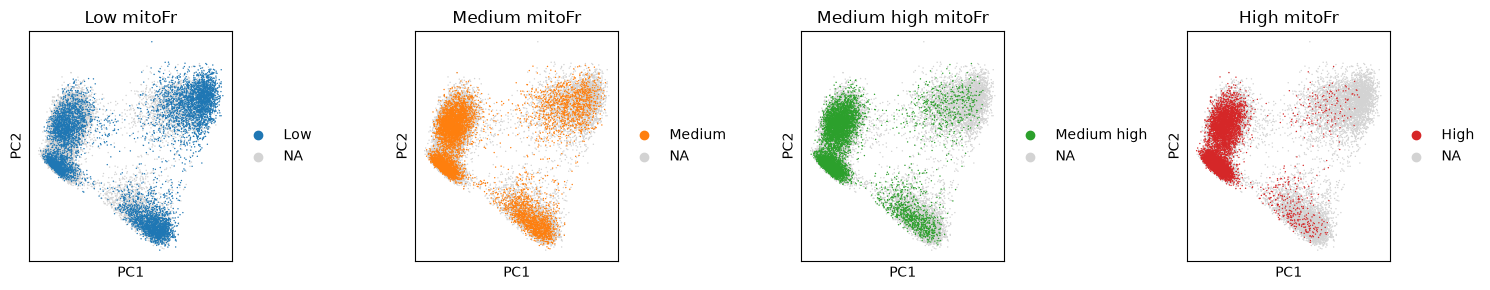

In [28]:
# Create plot with the correct dimensions
fig, axes = plt.subplots(1, 4, figsize=(15, 3))

# Plot the PCA colored by cell cycle phase
sc.pl.pca(adata_phase, color = "mitoFr", 
          groups = "Low", ax = axes[0], 
          show = False, title = "Low mitoFr")
sc.pl.pca(adata_phase, color = "mitoFr", 
          groups = "Medium", ax = axes[1], 
          show = False, title = "Medium mitoFr")
sc.pl.pca(adata_phase, color = "mitoFr", 
          groups = "Medium high", ax = axes[2], 
          show = False, title = "Medium high mitoFr")
sc.pl.pca(adata_phase, color = "mitoFr", 
          groups = "High", ax = axes[3], 
          show = False, title = "High mitoFr")

plt.tight_layout()
plt.show()

In [29]:
adata_phase.write_h5ad("data/adata_phase.h5ad")